# Детекция и сегментация планктонных организмов

**Цель работы:** изучить микроскопические фотографии планктона, проверить влияние аугментаций и сравнить работу YOLO11n, Faster R-CNN, GrabCut и SAM 2.1.

План работы: анализ изображений → аугментации → детекция → сегментация → сравнение результатов.  
Для сравнения использованы предобученные модели YOLO11n и Faster R-CNN. Обе модели изначально обучены на датасете COCO, который не содержит отдельных классов планктонных организмов. В работе проверяется, как эти модели справляются с изображениями планктона без дополнительного обучения.

[Исходные фотографии](https://drive.google.com/drive/folders/1LT2NdDSULHiW3FwzT63ewgVO3pwRRhOW?usp=sharing). У датасета нет проверенных прямоугольников и масок, поэтому оценить точность по mAP, Precision или Recall нельзя. Ниже сравниваются время обработки, количество рамок, их устойчивость и визуальные ошибки.

## Подготовка

Использован Python 3.11. Фотографии читаются из `data/raw/`, а результаты сохраняются в `results/`. Если CUDA доступна, детекторы и SAM запускаются на видеокарте.

Чтобы сравнение было воспроизводимым, фиксируем генератор случайных чисел и одинаковые настройки для обеих моделей.

In [1]:
from pathlib import Path
import json
import random
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image, ImageDraw, ImageEnhance, ImageFilter, ImageOps
from ultralytics import YOLO
from torchvision.models.detection import (
    FasterRCNN_ResNet50_FPN_V2_Weights,
    fasterrcnn_resnet50_fpn_v2,
)
from torchvision.transforms.functional import to_tensor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = Path.cwd()
DATA_DIR = ROOT / 'data' / 'raw'
RESULTS_DIR = ROOT / 'results'
EDA_DIR = RESULTS_DIR / 'eda'
AUG_DIR = RESULTS_DIR / 'augmentations'
DET_DIR = RESULTS_DIR / 'detections'
SEG_DIR = RESULTS_DIR / 'segmentation'
TABLE_DIR = RESULTS_DIR / 'tables'

for folder in [EDA_DIR, AUG_DIR, DET_DIR, SEG_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
MAX_SIDE = 1280
N_EXPERIMENT_IMAGES = 8
CONF_THRESHOLD = 0.10
MAX_DETECTIONS = 20

print('PyTorch:', torch.__version__)
print('Устройство:', DEVICE)
if DEVICE == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Устройство: cuda
GPU: NVIDIA GeForce RTX 5080


In [2]:
extensions = {'.jpg', '.jpeg', '.png', '.webp', '.tif', '.bmp'}
image_paths = sorted(
    path for path in DATA_DIR.rglob('*')
    if path.is_file() and path.suffix.lower() in extensions
)

print(f'Найдено изображений: {len(image_paths)}')
if not image_paths:
    raise ValueError(f'В папке {DATA_DIR} не найдены фотографии')

Найдено изображений: 189


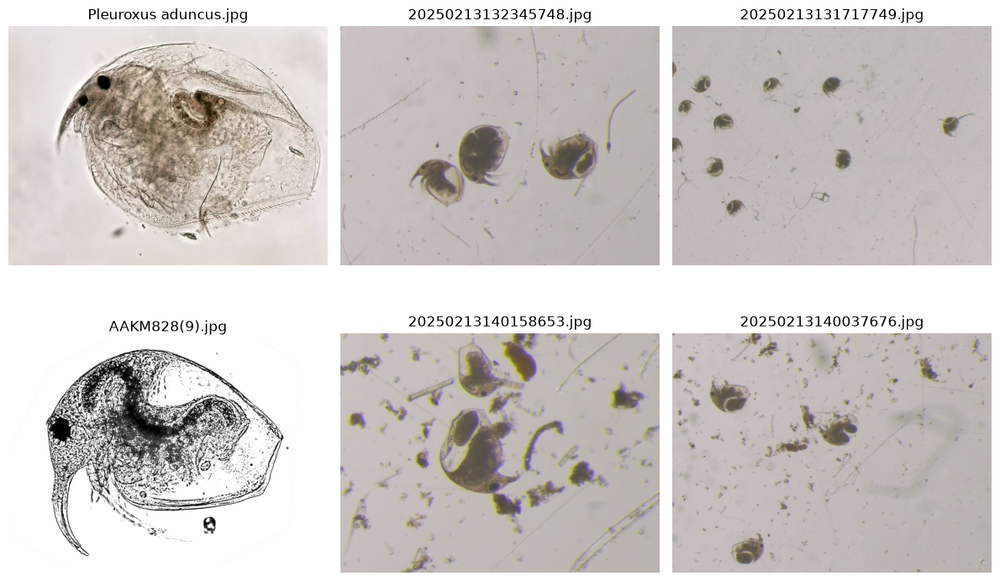

In [3]:
sample_paths = random.sample(
    image_paths,
    min(6, len(image_paths))
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, path in zip(axes.flat, sample_paths):
    with Image.open(path) as img:
        ax.imshow(img.convert('RGB'))

    ax.set_title(path.name)
    ax.axis('off')

for ax in axes.flat[len(sample_paths):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [4]:
records = []

for path in image_paths:
    try:
        with Image.open(path) as img:
            width, height = img.size
            mode = img.mode

        records.append({
            'filename': path.name,
            'image_id': path.relative_to(DATA_DIR).as_posix(),
            'path': str(path),
            'width': width,
            'height': height,
            'aspect_ratio': width / height,
            'pixels': width * height,
            'mode': mode,
            'file_size_kb': path.stat().st_size / 1024,
        })
    except (OSError, ValueError) as error:
        print(f'Не удалось прочитать {path}: {error}')

df = pd.DataFrame(records)
df[['filename', 'width', 'height', 'mode']].head()

,filename,width,height,mode
0,0005.jpg,2592,1944,RGB
1,20250213131616824.jpg,2048,1536,RGB
2,20250213131626559.jpg,2048,1536,RGB
3,20250213131634306.jpg,2048,1536,RGB
4,20250213131652198.jpg,2048,1536,RGB


In [5]:
df.describe()

,width,height,aspect_ratio,pixels,file_size_kb
count,189.000000,189.000000,189.000000,1.890000e+02,189.000000
mean,2172.640212,1685.005291,1.285074,3.837786e+06,2119.776450
std,533.096203,360.429642,0.133847,1.722341e+06,5057.288898
min,482.000000,572.000000,0.679831,3.417380e+05,165.200195
25%,2048.000000,1536.000000,1.333333,3.145728e+06,435.343750
50%,2048.000000,1536.000000,1.333333,3.145728e+06,730.181641
75%,2592.000000,1944.000000,1.333333,5.038848e+06,1978.285156
max,3584.000000,2748.000000,1.577951,9.848832e+06,28854.091797


**Наблюдение.** В папке 189 файлов. Большинство снимков цветные и имеют схожее соотношение сторон, но разрешения отличаются. Перед детекцией изображения будем уменьшать до длинной стороны не более 1280 пикселей, сохраняя пропорции.

## 1. Анализ изображений и аугментации

### Размеры фотографий

Сначала посмотрим разрешение и ориентацию снимков. Это поможет выбрать одинаковый размер входа для моделей.

Количество разных пар «ширина × высота»:

In [6]:
print('Уникальных разрешений:', df[['width', 'height']].drop_duplicates().shape[0])

Уникальных разрешений: 48


Самые распространённые размеры:

In [7]:
print('Наиболее частые разрешения:')
print(df.value_counts(subset=['width', 'height']).head())

Наиболее частые разрешения:
width  height
2592   1944      69
2048   1536      65
3584   2748       7
2288   1712       3
1417   1061       2
Name: count, dtype: int64


Описательная статистика ширины и высоты:

In [8]:
print('Статистика размеров:')
display(df[['width', 'height']].describe())

Статистика размеров:


,width,height
count,189.000000,189.000000
mean,2172.640212,1685.005291
std,533.096203,360.429642
min,482.000000,572.000000
25%,2048.000000,1536.000000
50%,2048.000000,1536.000000
75%,2592.000000,1944.000000
max,3584.000000,2748.000000


Распределение фотографий по ориентации:

In [9]:
horizontal_pct = (df['width'] > df['height']).mean() * 100
other_pct = 100 - horizontal_pct

print(f'Горизонтальных изображений: {horizontal_pct:.1f}%')
print(f'Остальных (вертикальные и квадратные): {other_pct:.1f}%')

Горизонтальных изображений: 93.7%
Остальных (вертикальные и квадратные): 6.3%


**Вывод по разрешениям.** Среди всех 189 файлов найдено 48 размеров. Чаще всего встречаются 2592 × 1944 (69 шт.) и 2048 × 1536 (65 шт.); вместе это 70,9% файлов. Горизонтальных изображений — 93,7%.

В папке также есть **21 файл с признаками производных фрагментов** (`_obj_`, `_class_`, `_conf_` в имени). Для экспериментов с моделями они исключены, чтобы не смешивать исходные фотографии с заранее вырезанными объектами. Остаётся **168 исходных снимков**, среди которых 27 разных разрешений; горизонтальных — около 97%. Обзор всей папки и основной набор для детекции отличаются.

### Контрастность

Для каждого кадра переведём изображение в оттенки серого и посчитаем стандартное отклонение яркости (`np.std`). Чем сильнее различаются яркости пикселей, тем выше этот показатель. Он характеризует весь снимок, а не только контур организма.

In [10]:
with Image.open(image_paths[0]) as img:
    gray = img.convert('L')
    img_array = np.array(gray)

mean_brightness = np.mean(img_array)
contrast = np.std(img_array)

print(f'Средняя яркость: {mean_brightness:.2f}')
print(f'Контрастность: {contrast:.2f}')

Средняя яркость: 108.74
Контрастность: 43.69


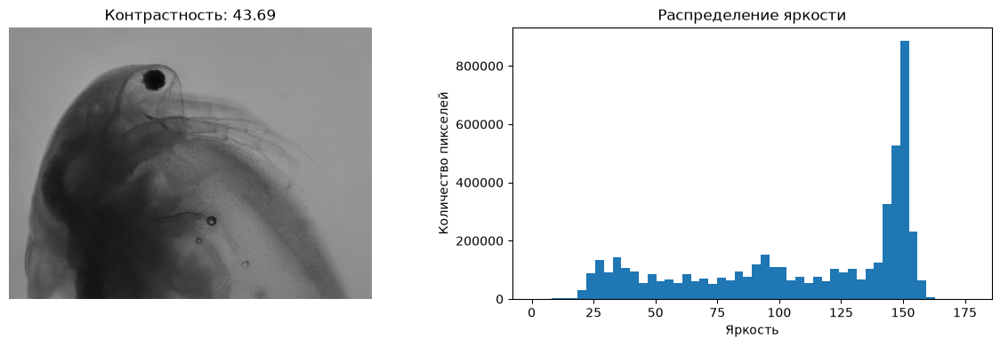

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(img_array, cmap='gray', vmin=0, vmax=255)
axes[0].set_title(f'Контрастность: {contrast:.2f}')
axes[0].axis('off')

axes[1].hist(img_array.ravel(), bins=50)
axes[1].set_title('Распределение яркости')
axes[1].set_xlabel('Яркость')
axes[1].set_ylabel('Количество пикселей')

plt.tight_layout()
plt.show()

In [12]:
contrasts = []

for path in df['path']:
    with Image.open(path) as img:
        gray = img.convert('L')
        img_array = np.array(gray)

        contrast = np.std(img_array)

        contrasts.append(contrast)

df['contrast'] = contrasts

df['contrast'].describe()

count    189.000000
mean      37.188979
std       17.291111
min       12.105731
25%       24.641522
50%       33.136600
75%       46.094074
max       94.982321
Name: contrast, dtype: float64

**Вывод по контрастности.** Для всех 189 файлов среднее стандартное отклонение яркости равно **37,19**, медиана — **33,14** (диапазон 12,11–94,98). Среди **168 исходных фотографий** среднее ниже — **35,81**, медиана **31,17**. Значит, несколько производных файлов влияют на общую статистику.

В низкоконтрастных кадрах прозрачные края организмов теряются на фоне. Поэтому дальше посмотрим несколько снимков из разных частей распределения.

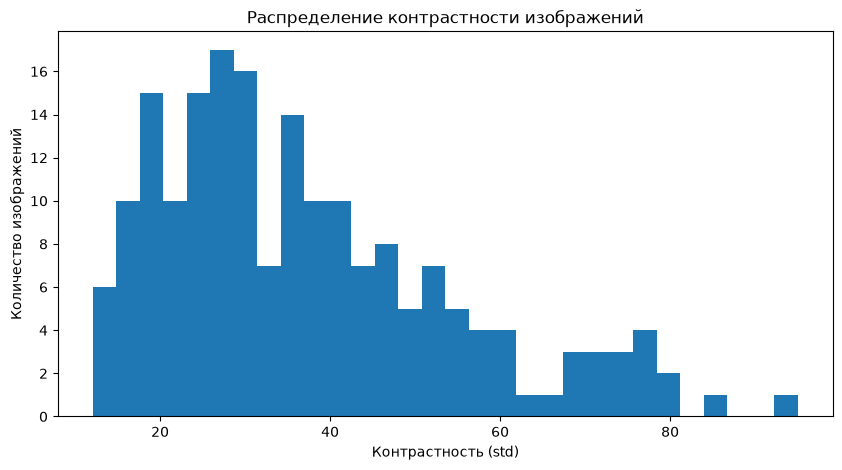

In [13]:
plt.figure(figsize=(10, 5))

plt.hist(df['contrast'], bins=30)

plt.xlabel('Контрастность (std)')
plt.ylabel('Количество изображений')
plt.title('Распределение контрастности изображений')

plt.show()

In [14]:
q1 = df['contrast'].quantile(0.25)
small_contrast = df[df['contrast'] < q1]
print(f'Изображений с контрастностью ниже Q1 ({q1:.2f}): {len(small_contrast)}')

Изображений с контрастностью ниже Q1 (24.64): 47


In [15]:
df.nsmallest(5, 'contrast')[['filename', 'width', 'height', 'contrast']]

filename,width,height,contrast
20250213135317232.jpg,2048,1536,12.11
20250213135309229.jpg,2048,1536,12.20
20250213131844327.jpg,2048,1536,12.91
20250213131717749.jpg,2048,1536,13.62
20250213135936465.jpg,2048,1536,13.98


In [16]:
q1, q3 = df['contrast'].quantile([0.25, 0.75])
small_contrast = df[df['contrast'] <= q1]
mid_contrast = df[df['contrast'].between(q1, q3, inclusive='neither')]
high_contrast = df[df['contrast'] >= q3]

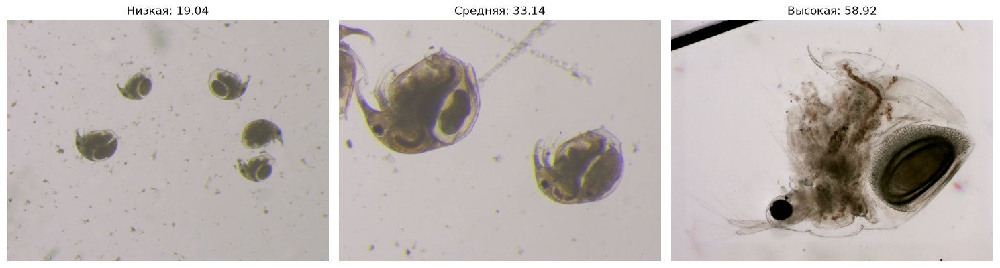

In [17]:
groups = {
    'Низкая': small_contrast,
    'Средняя': mid_contrast,
    'Высокая': high_contrast
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, group) in zip(axes, groups.items()):
    group = group.sort_values('contrast')
    row = group.iloc[len(group) // 2]

    with Image.open(row['path']) as img:
        ax.imshow(img.convert('RGB'))

    ax.set_title(f'{name}: {row["contrast"]:.2f}')
    ax.axis('off')

plt.tight_layout()
plt.show()

### Фон, размеры объектов и перекрытия

Выберем 12 изображений от самой низкой контрастности до самой высокой. По ним оценим фон, размер организмов относительно кадра, соприкосновения и обрезанные края. Для всего датасета таких меток нет, поэтому здесь используется визуальная оценка, а не подсчёт точной площади организмов.

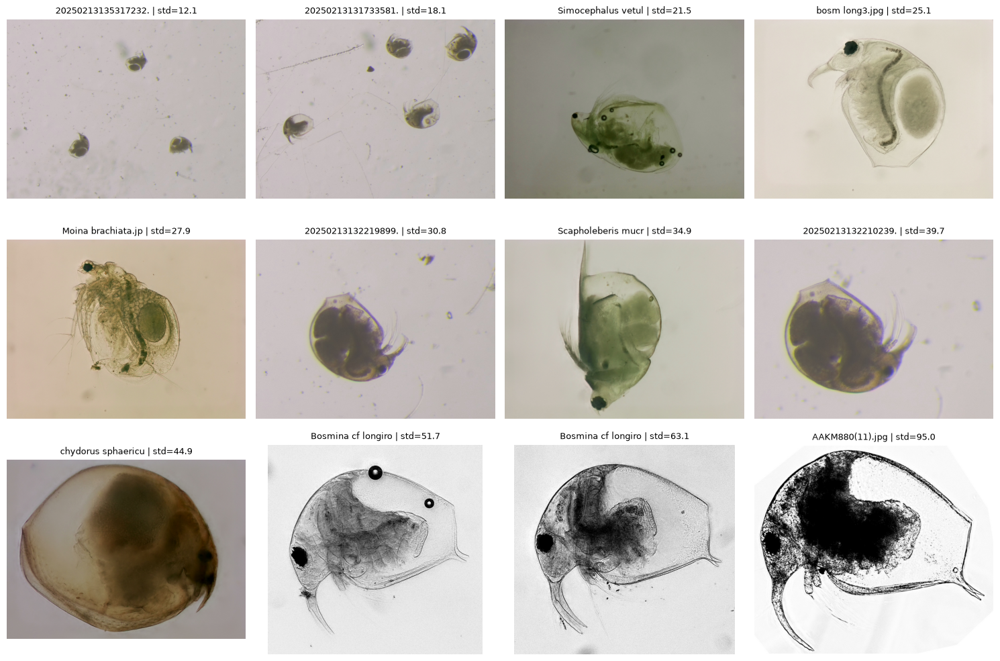

Таблица для визуальной оценки: results/tables/eda_review.csv


In [18]:
ordered = df.sort_values('contrast').reset_index(drop=True)
indices = np.linspace(0, len(ordered) - 1, min(12, len(ordered)), dtype=int)
eda_examples = ordered.iloc[indices]

fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, (_, row) in zip(axes.flat, eda_examples.iterrows()):
    with Image.open(row['path']) as img:
        ax.imshow(img.convert('RGB'))
    label = str(row['filename'])[:18]
    std_value = row['contrast']
    ax.set_title(f'{label} | std={std_value:.1f}', fontsize=9)
    ax.axis('off')
for ax in axes.flat[len(eda_examples):]:
    ax.axis('off')
plt.tight_layout()
fig.savefig(EDA_DIR / 'eda_contact_sheet.png', dpi=150)
plt.show()

eda_review_path = TABLE_DIR / 'eda_review.csv'
if not eda_review_path.exists():
    review = eda_examples[['image_id', 'filename', 'contrast']].copy()
    for column in ['background', 'object_size', 'overlap', 'cropped_by_border', 'notes']:
        review[column] = ''
    review.to_csv(eda_review_path, index=False)
print('Таблица для визуальной оценки:', eda_review_path.relative_to(ROOT))

**Что заметно на снимках.** На `20250213135317232.jpg` несколько небольших организмов занимают лишь часть кадра, а вокруг много мелких частиц. У `Simocephalus vetulus.jpg` тело крупнее и имеет полупрозрачную границу. На `20250213131733581.jpg` видны волокна, похожие на тонкие отростки.

На некоторых снимках объект подходит к границе кадра; на `20250213135210060.jpg` организмы расположены близко друг к другу. Это сложные случаи для выделения отдельных объектов. Два изображения с `_obj_` в названии — производные фрагменты, в детекцию они не включены.

In [19]:
def load_image(path):
    with Image.open(path) as img:
        return img.convert('RGB').copy()


def resize_image(img, max_side=MAX_SIDE):
    if max(img.size) <= max_side:
        return img.copy()
    scale = max_side / max(img.size)
    size = (round(img.width * scale), round(img.height * scale))
    return img.resize(size, Image.Resampling.LANCZOS)


def augment(img, name):
    if name.startswith('brightness_'):
        return ImageEnhance.Brightness(img).enhance(float(name.split('_')[1]))
    if name.startswith('contrast_'):
        return ImageEnhance.Contrast(img).enhance(float(name.split('_')[1]))
    if name.startswith('gamma_'):
        g = float(name.split('_')[1])
        array = (np.asarray(img, dtype=np.float32) / 255) ** g * 255
        return Image.fromarray(np.clip(array, 0, 255).astype('uint8'))
    if name.startswith('rotate_'):
        angle = float(name.split('_')[1])
        return img.rotate(angle, resample=Image.Resampling.BILINEAR,
                          fillcolor=(255, 255, 255))
    if name.startswith('noise_'):
        sigma = float(name.split('_')[1])
        noise = np.random.default_rng(SEED).normal(0, sigma, np.asarray(img).shape)
        array = np.clip(np.asarray(img, dtype=float) + noise, 0, 255).astype('uint8')
        return Image.fromarray(array)
    if name.startswith('blur_'):
        return img.filter(ImageFilter.GaussianBlur(float(name.split('_')[1])))
    if name == 'flip':
        return ImageOps.mirror(img)
    raise ValueError(f'Неизвестная аугментация: {name}')

# Широкий диапазон для визуального анализа
aug_examples = [
    'original', 'brightness_0.7', 'brightness_1.2',
    'contrast_0.7', 'contrast_1.3', 'gamma_0.7',
    'noise_10', 'noise_25',
    'blur_1', 'blur_3', 'flip', 'rotate_15'
]

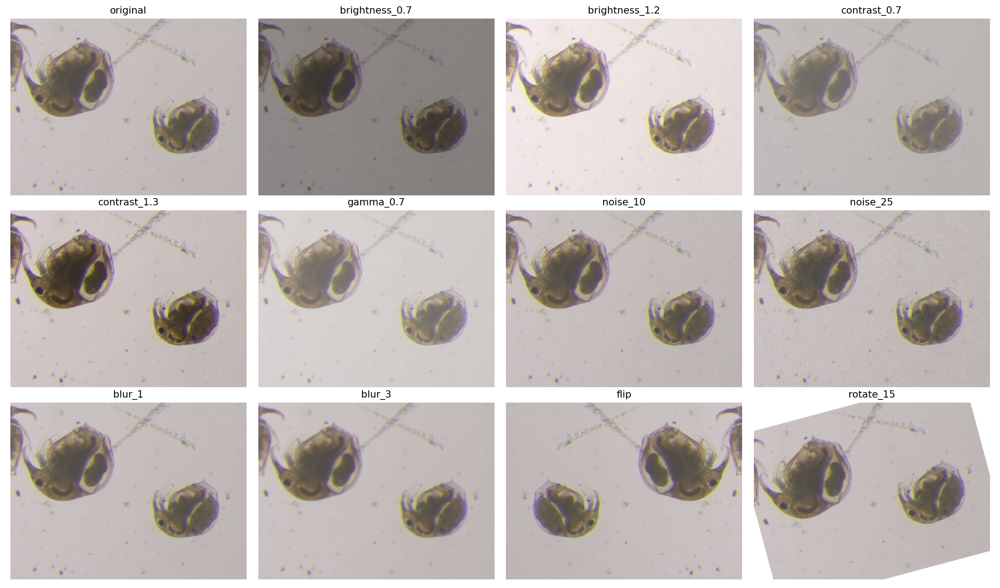

In [20]:
# Возьмём изображение из центральной части распределения
sorted_df = df.sort_values('contrast')
middle_image = sorted_df.iloc[len(sorted_df) // 2]

example = load_image(middle_image['path'])
example = resize_image(example)

fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for ax, name in zip(axes.flat, aug_examples):
    img = example if name == 'original' else augment(example, name)
    ax.imshow(img)
    ax.set_title(name)
    ax.axis('off')
    img.save(AUG_DIR / f'{name}.png')
plt.tight_layout()
fig.savefig(AUG_DIR / 'augmentation_grid.png', dpi=150)
plt.show()

**Вывод по аугментациям.** Снижение контраста делает прозрачные границы менее заметными. При шуме `noise_25` появляются частицы, похожие на мелкий мусор, а размытие `blur_3` скрывает тонкие отростки. Гамма-коррекция меняет распределение яркости, отражение сохраняет форму, а при повороте на 15° часть изображения заполняется светлым фоном.

Для количественного сравнения детекторов взяты пять умеренных преобразований: `brightness_1.2`, `contrast_0.7`, `noise_10`, `blur_1` и `flip`. Гамма и поворот показаны только здесь, чтобы не расширять основной эксперимент.

## 2. Детекция: YOLO11n и Faster R-CNN

YOLO11n относится к одноэтапным детекторам, Faster R-CNN с ResNet-50 FPN V2 — к двухэтапным. Обе модели используют веса COCO, а не обучаются на этих фотографиях.

Классы COCO не содержат планктонных организмов. Поэтому я сравниваю в первую очередь **расположение рамок**, а не названия классов. Для обеих моделей выбран низкий порог `confidence = 0,10`: так сохраняется больше кандидатов, но возрастает число ложных обнаружений.

In [21]:
print('Загружаем YOLO...')
yolo = YOLO('yolo11n.pt')
print('Загружаем Faster R-CNN...')
frcnn_weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
frcnn = fasterrcnn_resnet50_fpn_v2(weights=frcnn_weights)
frcnn = frcnn.to(DEVICE).eval()
print('Обе модели загружены')

Загружаем YOLO...
Загружаем Faster R-CNN...
Обе модели загружены


In [22]:
def sync_gpu():
    if DEVICE == 'cuda':
        torch.cuda.synchronize()


def detect_yolo(img):
    # Передаём PIL: не требуется преобразовывать RGB в BGR
    sync_gpu()
    start = time.perf_counter()
    result = yolo.predict(img, imgsz=MAX_SIDE, conf=CONF_THRESHOLD,
                          max_det=MAX_DETECTIONS, device=DEVICE, verbose=False)[0]
    sync_gpu()
    seconds = time.perf_counter() - start
    boxes = result.boxes
    rows = []
    for box, score, cls in zip(boxes.xyxy.cpu().numpy(),
                               boxes.conf.cpu().numpy(), boxes.cls.cpu().numpy()):
        rows.append({'box': box.tolist(), 'score': float(score), 'class_id': int(cls)})
    return rows, seconds


@torch.inference_mode()
def detect_frcnn(img):
    sync_gpu()
    start = time.perf_counter()
    image_tensor = to_tensor(img).to(DEVICE)
    result = frcnn([image_tensor])[0]
    sync_gpu()
    seconds = time.perf_counter() - start
    rows = []
    for box, score, cls in zip(result['boxes'].cpu().numpy(),
                               result['scores'].cpu().numpy(), result['labels'].cpu().numpy()):
        if float(score) < CONF_THRESHOLD:
            continue
        rows.append({'box': box.tolist(), 'score': float(score), 'class_id': int(cls)})
        if len(rows) == MAX_DETECTIONS:
            break
    return rows, seconds


def draw_boxes(img, objects):
    out = img.copy()
    draw = ImageDraw.Draw(out)
    for obj in objects:
        box = [int(x) for x in obj['box']]
        draw.rectangle(box, outline='red', width=3)
        x1, y1 = box[:2]
        if 'score' in obj:
            score = obj['score']
            draw.text((x1 + 3, max(0, y1 - 14)), f'{score:.2f}', fill='red')
    return out

### Схема эксперимента

Из 168 исходных фотографий выбраны **8 кадров по возрастанию контрастности**, чтобы среди них были и светлые, и контрастные примеры. Это небольшая намеренно разнообразная выборка, а не случайная репрезентативная оценка всего набора.

Для каждой модели сравниваем исходные снимки и пять одинаковых преобразований. Получается четыре группы: YOLO/исходные, YOLO/аугментированные, Faster R-CNN/исходные, Faster R-CNN/аугментированные. Всего 8 × 6 × 2 = **96 запусков**.

In [23]:
# Для моделей оставляем только исходные фотографии
original_df = df[~df['filename'].str.contains('_obj_|_class_|_conf_', regex=True)].copy()
original_df[['filename', 'image_id', 'width', 'height', 'contrast', 'aspect_ratio', 'pixels']].to_csv(
    TABLE_DIR / 'eda_images.csv', index=False
)
ordered = original_df.sort_values('contrast').reset_index(drop=True)
indices = np.linspace(0, len(ordered) - 1,
                      min(N_EXPERIMENT_IMAGES, len(ordered)), dtype=int)
experiment_df = ordered.iloc[indices].reset_index(drop=True)
experiment_df[['image_id', 'filename', 'contrast']].to_csv(
    TABLE_DIR / 'experiment_sample.csv', index=False
)

# Одинаковые аугментации для обеих моделей
experiment_augs = ['original', 'brightness_1.2', 'contrast_0.7',
                   'noise_10', 'blur_1', 'flip']

# Прогрев для более корректного измерения времени
warmup_img = resize_image(load_image(experiment_df.iloc[0]['path']))
_ = detect_yolo(warmup_img)
_ = detect_frcnn(warmup_img)

all_boxes = []
run_info = []

for _, row in experiment_df.iterrows():
    original = resize_image(load_image(row['path']))
    image_id = row['image_id']
    stem = Path(image_id).stem
    print('Обработка:', image_id)

    for aug in experiment_augs:
        img = original if aug == 'original' else augment(original, aug)
        for model_name, model_func in [('YOLO', detect_yolo), ('Faster R-CNN', detect_frcnn)]:
            objects, seconds = model_func(img)
            run_info.append({
                'image_id': image_id,
                'model': model_name,
                'augmentation': aug,
                'group': 'original' if aug == 'original' else 'augmented',
                'seconds': seconds,
                'n_detections': len(objects)
            })
            for obj in objects:
                x1, y1, x2, y2 = obj['box']
                all_boxes.append({
                    'image_id': image_id, 'model': model_name, 'augmentation': aug,
                    'x1': x1, 'y1': y1, 'x2': x2, 'y2': y2,
                    'confidence': obj['score'], 'class_id': obj['class_id']
                })

            # Сохраняем результат каждого запуска, даже если рамок нет
            safe = stem.replace(' ', '_')
            folder = DET_DIR / model_name.replace(' ', '_')
            folder.mkdir(exist_ok=True)
            draw_boxes(img, objects).save(folder / f'{safe}__{aug}.png')

runs_df = pd.DataFrame(run_info)
boxes_df = pd.DataFrame(all_boxes, columns=[
    'image_id', 'model', 'augmentation', 'x1', 'y1', 'x2', 'y2',
    'confidence', 'class_id'
])
runs_df.to_csv(TABLE_DIR / 'detection_runs.csv', index=False)
boxes_df.to_csv(TABLE_DIR / 'detection_boxes.csv', index=False)
print('Запусков:', len(runs_df), '| рамок:', len(boxes_df))
display(runs_df.head())

Обработка: 20250213135317232.jpg
Обработка: 20250213135713622.jpg
Обработка: 20250213135210060.jpg
Обработка: Macrothrix hirsuticornis2.jpg
Обработка: bosmina coregoni.jpg
Обработка: Bosmina longirostris 2.jpg
Обработка: Daphnia pulex.jpg
Обработка: AAKM880(11).jpg
Запусков: 96 | рамок: 504


,image_id,model,augmentation,group,seconds,n_detections
0,20250213135317232.jpg,YOLO,original,original,0.010690,4
1,20250213135317232.jpg,Faster R-CNN,original,original,0.031795,3
2,20250213135317232.jpg,YOLO,brightness_1.2,augmented,0.011784,4
3,20250213135317232.jpg,Faster R-CNN,brightness_1.2,augmented,0.030839,3
4,20250213135317232.jpg,YOLO,contrast_0.7,augmented,0.011223,2


**Промежуточный итог:** выполнено 96 запусков (48 для YOLO и 48 для Faster R-CNN). В `detection_boxes.csv` записаны **504 предсказанные рамки**. Число рамок само по себе не показывает, сколько организмов обнаружено правильно.

### Примеры детекции

Посмотрим на одинаковые кадры с рамками двух моделей. Красным показаны найденные прямоугольники; подписи рядом с ними — confidence модели.

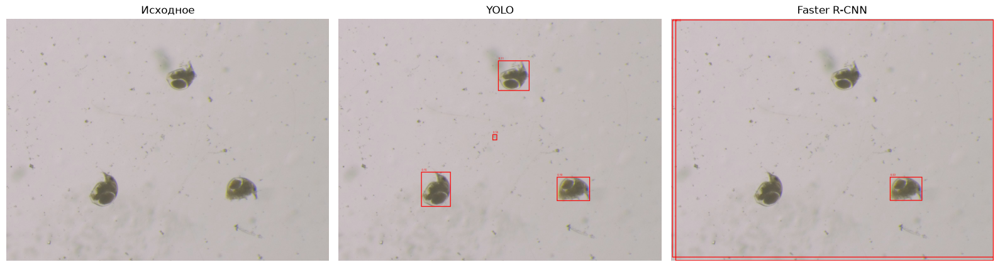

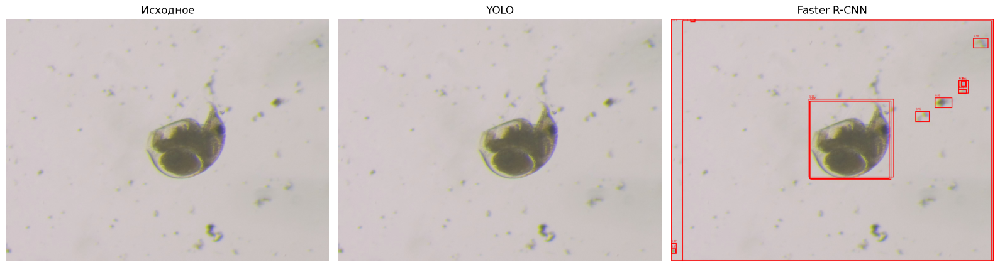

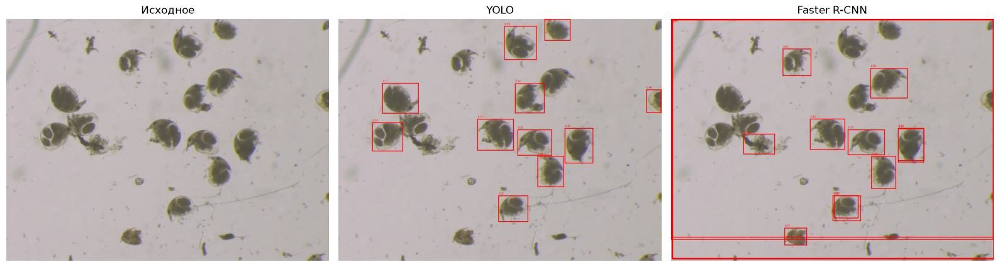

In [24]:
# Показываем исходное изображение и результаты двух моделей
for _, row in experiment_df.head(3).iterrows():
    img = resize_image(load_image(row['path']))
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    axes[0].imshow(img)
    axes[0].set_title('Исходное')

    for ax, model_name in zip(axes[1:], ['YOLO', 'Faster R-CNN']):
        selected = boxes_df[
            (boxes_df['image_id'] == row['image_id']) &
            (boxes_df['model'] == model_name) &
            (boxes_df['augmentation'] == 'original')
        ]
        objects = [
            {'box': [r['x1'], r['y1'], r['x2'], r['y2']], 'score': r['confidence']}
            for _, r in selected.iterrows()
        ]
        ax.imshow(draw_boxes(img, objects))
        ax.set_title(model_name)

    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### Время, число рамок и устойчивость

После загрузки и прогрева моделей замеряется время инференса. Для каждого исходного прямоугольника ищется максимальный IoU с рамками на аугментированном кадре. После отражения координаты возвращаются обратно.

Этот IoU показывает, насколько **сохраняется расположение предсказаний**, а не их правильность. Также метрика односторонняя: новые лишние рамки после аугментации напрямую её не уменьшают.

In [25]:
def box_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    union = area_a + area_b - intersection
    return intersection / union if union else 0


def get_boxes(image_id, model_name, aug):
    subset = boxes_df[
        (boxes_df['image_id'] == image_id) &
        (boxes_df['model'] == model_name) &
        (boxes_df['augmentation'] == aug)
    ]
    return subset[['x1', 'y1', 'x2', 'y2']].to_numpy()


stability = []
for _, row in experiment_df.iterrows():
    image_id = row['image_id']
    width = resize_image(load_image(row['path'])).width
    for model_name in ['YOLO', 'Faster R-CNN']:
        original_boxes = get_boxes(image_id, model_name, 'original')
        for aug in experiment_augs[1:]:
            aug_boxes = get_boxes(image_id, model_name, aug)
            if aug == 'flip':
                # Координаты отражённого изображения возвращаем к оригиналу
                aug_boxes = np.array([[width - b[2], b[1], width - b[0], b[3]]
                                      for b in aug_boxes]).reshape(-1, 4)
            # Каждый исходный box сопоставляем с наиболее близким предсказанием
            best = [max([box_iou(b, x) for x in aug_boxes], default=0)
                    for b in original_boxes]
            stability.append({
                'image_id': image_id, 'model': model_name, 'augmentation': aug,
                'mean_best_iou': np.mean(best) if best else np.nan
            })

stability_df = pd.DataFrame(stability)
stability_df.to_csv(TABLE_DIR / 'bbox_stability.csv', index=False)

summary_df = (runs_df.groupby(['model', 'group'], as_index=False)
              .agg(n_runs=('image_id', 'count'),
                   mean_seconds=('seconds', 'mean'),
                   mean_detections=('n_detections', 'mean')))
display(summary_df.round(3))
summary_df.to_csv(TABLE_DIR / 'detection_summary.csv', index=False)

print('Устойчивость к отдельным аугментациям (если исходные рамки были):')
display(stability_df.groupby(['model', 'augmentation'])['mean_best_iou'].mean().round(3))

,model,group,n_runs,mean_seconds,mean_detections
0,Faster R-CNN,augmented,40,0.034,7.425
1,Faster R-CNN,original,8,0.035,8.625
2,YOLO,augmented,40,0.012,2.900
3,YOLO,original,8,0.014,2.750


Устойчивость к отдельным аугментациям (если исходные рамки были):


model         augmentation  
Faster R-CNN  blur_1            0.863
              brightness_1.2    0.826
              contrast_0.7      0.822
              flip              0.749
              noise_10          0.781
YOLO          blur_1            0.666
              brightness_1.2    0.815
              contrast_0.7      0.597
              flip              0.656
              noise_10          0.821
Name: mean_best_iou, dtype: float64

#### Как аугментации повлияли на детекцию

Сравним среднее число рамок на одно изображение для каждой аугментации. Это не метрика точности: после добавления шума модель может находить больше мелких частиц фона.

In [ ]:
by_aug = (runs_df.groupby(['augmentation', 'model'])['n_detections']
          .mean().unstack('model').round(2))
display(by_aug.loc[experiment_augs])

model,augmentation,Faster R-CNN,YOLO
,original,8.62,2.75
,brightness_1.2,7.25,2.88
,contrast_0.7,6.75,2.25
,noise_10,8.88,3.88
,blur_1,7.50,2.50
,flip,6.75,3.00


На восьми выбранных снимках снижение контраста уменьшило число рамок обеих моделей. Шум `noise_10` увеличил его и у YOLO, и у Faster R-CNN. По примерам видно, что часть новых рамок ложная, поэтому интерпретировать этот рост как повышение качества нельзя.

При вычислении устойчивости по IoU для YOLO учитывались только семь кадров: на одном исходном изображении она не нашла ни одной рамки. У Faster R-CNN в расчёте участвовали все восемь.

**Сравнение на исходных кадрах.** YOLO обрабатывала изображение в среднем за **13,5 мс**, Faster R-CNN — за **35,4 мс**. YOLO дала 22 рамки, Faster R-CNN — 69 (на одних и тех же восьми фотографиях). Более высокое число предсказаний Faster R-CNN не означает, что она нашла больше настоящих организмов: часть прямоугольников дублируется или захватывает фон.

### Визуальные ошибки

На `20250213135713622.jpg` YOLO не выдала ни одной рамки, а Faster R-CNN нашла основной организм вместе с посторонними деталями. На `Macrothrix hirsuticornis2.jpg` YOLO выделяет отдельные тёмные части тела, а Faster R-CNN создаёт несколько пересекающихся рамок. На `20250213135210060.jpg` часть близко стоящих организмов остаётся без рамок.

Замечания по восьми экспериментальным фотографиям собраны в `results/tables/detection_review.csv`. Они сделаны по сохранённым визуализациям, а не выведены из confidence.

In [26]:
review_file = TABLE_DIR / 'detection_review.csv'
if not review_file.exists():
    review = experiment_df[['image_id', 'filename']].copy()
    for col in ['false_detections', 'missed_organisms', 'small_objects', 'overlap', 'comment']:
        review[col] = ''
    review.to_csv(review_file, index=False)
print('Для ручного анализа:', review_file.relative_to(ROOT))

Для ручного анализа: results/tables/detection_review.csv


## 3. Сегментация: GrabCut и SAM 2.1

Для каждого прямоугольника два метода получают одинаковую область изображения: GrabCut начинает выделение переднего плана внутри неё, SAM 2.1 использует её как подсказку `box`.

Здесь проверены **11 рамок на 4 фотографиях**, выбранных из результатов детекции. Часть рамок не охватывает целый организм, поэтому сравним не только численный IoU масок, но и сами наложения на изображение.

In [27]:
# При необходимости сюда можно вручную записать рамки для других снимков.
# Координаты указаны на изображениях после resize_image (длинная сторона <= 1280).
# Пример формата: {'photo.jpg': [[100, 120, 500, 650]]}
manual_boxes = {}

MAX_SEGMENT_IMAGES = 4
MAX_BOXES_PER_IMAGE = 3
segment_inputs = []

for _, row in experiment_df.head(MAX_SEGMENT_IMAGES).iterrows():
    img = resize_image(load_image(row['path']))
    print(row['image_id'], 'уменьшенный размер:', img.size)
    selected = []
    # Ручные рамки имеют приоритет
    values = manual_boxes.get(row['image_id'], manual_boxes.get(row['filename'], []))
    if values:
        selected = [(b, 'manual') for b in values[:MAX_BOXES_PER_IMAGE]]
    else:
        for model_name in ['YOLO', 'Faster R-CNN']:
            subset = boxes_df[
                (boxes_df['image_id'] == row['image_id']) &
                (boxes_df['model'] == model_name) &
                (boxes_df['augmentation'] == 'original')
            ].sort_values('confidence', ascending=False)
            # Убираем вырожденные рамки
            subset = subset[(subset['x2'] - subset['x1'] >= 8) &
                            (subset['y2'] - subset['y1'] >= 8)]
            if len(subset):
                selected = [
                    ([r['x1'], r['y1'], r['x2'], r['y2']], model_name)
                    for _, r in subset.head(MAX_BOXES_PER_IMAGE).iterrows()
                ]
                break

    for box, source in selected:
        segment_inputs.append({'image_id': row['image_id'],
                               'path': row['path'], 'box': box, 'source': source})

print('Подготовлено прямоугольников для сегментации:', len(segment_inputs))
if not segment_inputs:
    print('Модели не дали рамок на выбранных кадрах. Заполните manual_boxes и повторите ячейку.')

20250213135317232.jpg уменьшенный размер: (1280, 960)
20250213135713622.jpg уменьшенный размер: (1280, 960)
20250213135210060.jpg уменьшенный размер: (1280, 960)
Macrothrix hirsuticornis2.jpg уменьшенный размер: (1280, 960)
Подготовлено прямоугольников для сегментации: 11


In [28]:
def grabcut_mask(img, box):
    # GrabCut принимает прямоугольник (x, y, ширина, высота)
    array = np.asarray(img)
    height, width = array.shape[:2]
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1 = max(0, min(x1, width - 2))
    y1 = max(0, min(y1, height - 2))
    x2 = max(x1 + 1, min(x2, width - 1))
    y2 = max(y1 + 1, min(y2, height - 1))
    rect = (x1, y1, x2 - x1, y2 - y1)

    mask = np.zeros((height, width), np.uint8)
    bg = np.zeros((1, 65), np.float64)
    fg = np.zeros((1, 65), np.float64)
    # Ограничимся пятью итерациями для понятного эксперимента
    cv2.grabCut(array, mask, rect, bg, fg, 5, cv2.GC_INIT_WITH_RECT)
    return np.isin(mask, [cv2.GC_FGD, cv2.GC_PR_FGD]).astype('uint8')


def overlay_mask(img, mask):
    rgb = np.asarray(img, dtype=np.float32).copy()
    green = np.array([40, 220, 80])
    rgb[mask.astype(bool)] = 0.6 * rgb[mask.astype(bool)] + 0.4 * green
    return Image.fromarray(rgb.astype('uint8'))

### Запуск двух методов

Сначала вычисляем маску GrabCut, затем SAM 2.1. SAM получает подсказку-прямоугольник через `box`. У первого вызова SAM заметны накладные расходы (подготовка модели и признаков); это нужно учитывать при сравнении времени.

In [29]:
seg_records = []
if segment_inputs:
    from sam2.sam2_image_predictor import SAM2ImagePredictor
    sam = SAM2ImagePredictor.from_pretrained('facebook/sam2.1-hiera-tiny', device=DEVICE)

    for i, item in enumerate(segment_inputs):
        img = resize_image(load_image(item['path']))
        box = item['box']
        file_stem = Path(item['image_id']).stem.replace(' ', '_')
        prefix = f'{file_stem}__{i:02d}'

        sync_gpu()
        start = time.perf_counter()
        grab_mask = grabcut_mask(img, box)
        sync_gpu()
        grab_seconds = time.perf_counter() - start

        sync_gpu()
        start = time.perf_counter()
        with torch.inference_mode():
            sam.set_image(np.array(img, copy=True))
            masks, scores, _ = sam.predict(box=np.array(box), multimask_output=False)
        sync_gpu()
        sam_seconds = time.perf_counter() - start
        sam_mask = masks[0].astype('uint8')

        # Сохраняем маски и их наложения для проверки
        img.save(SEG_DIR / f'{prefix}_original.png')
        draw_boxes(img, [{'box': box}]).save(SEG_DIR / f'{prefix}_box.png')
        Image.fromarray(grab_mask * 255).save(SEG_DIR / f'{prefix}_grabcut_mask.png')
        Image.fromarray(sam_mask * 255).save(SEG_DIR / f'{prefix}_sam_mask.png')
        overlay_mask(img, grab_mask).save(SEG_DIR / f'{prefix}_grabcut_overlay.png')
        overlay_mask(img, sam_mask).save(SEG_DIR / f'{prefix}_sam_overlay.png')

        intersection = np.logical_and(grab_mask, sam_mask).sum()
        union = np.logical_or(grab_mask, sam_mask).sum()
        mask_agreement = intersection / union if union else np.nan

        for method, mask, seconds in [
            ('GrabCut', grab_mask, grab_seconds), ('SAM 2.1', sam_mask, sam_seconds)
        ]:
            seg_records.append({
                'image_id': item['image_id'], 'box_id': i, 'source': item['source'],
                'method': method, 'seconds': seconds,
                'mask_area_pct': 100 * mask.mean(),
                'agreement_iou': mask_agreement
            })

        image_id = item['image_id']
        source = item['source']
        print(f'{image_id} | {source} | GrabCut {grab_seconds:.2f} c | SAM {sam_seconds:.2f} c')

seg_df = pd.DataFrame(seg_records, columns=[
    'image_id', 'box_id', 'source', 'method', 'seconds',
    'mask_area_pct', 'agreement_iou'
])
seg_df.to_csv(TABLE_DIR / 'segmentation_results.csv', index=False)
print('Количество сохранённых результатов сегментации:', len(seg_df))

20250213135317232.jpg | YOLO | GrabCut 0.97 c | SAM 0.23 c
20250213135317232.jpg | YOLO | GrabCut 1.02 c | SAM 0.05 c
20250213135317232.jpg | YOLO | GrabCut 0.99 c | SAM 0.04 c
20250213135713622.jpg | Faster R-CNN | GrabCut 0.99 c | SAM 0.04 c
20250213135713622.jpg | Faster R-CNN | GrabCut 0.99 c | SAM 0.04 c
20250213135713622.jpg | Faster R-CNN | GrabCut 1.12 c | SAM 0.04 c
20250213135210060.jpg | YOLO | GrabCut 1.05 c | SAM 0.04 c
20250213135210060.jpg | YOLO | GrabCut 0.98 c | SAM 0.04 c
20250213135210060.jpg | YOLO | GrabCut 0.98 c | SAM 0.03 c
Macrothrix hirsuticornis2.jpg | YOLO | GrabCut 0.94 c | SAM 0.04 c
Macrothrix hirsuticornis2.jpg | YOLO | GrabCut 0.95 c | SAM 0.03 c
Количество сохранённых результатов сегментации: 22


**Получено:** 22 записи — по 11 масок GrabCut и SAM 2.1. Рамки с маленькими фрагментами фона не стоит оценивать как успешную сегментацию планктона. Ниже отдельно разберём подходящие и неподходящие примеры.

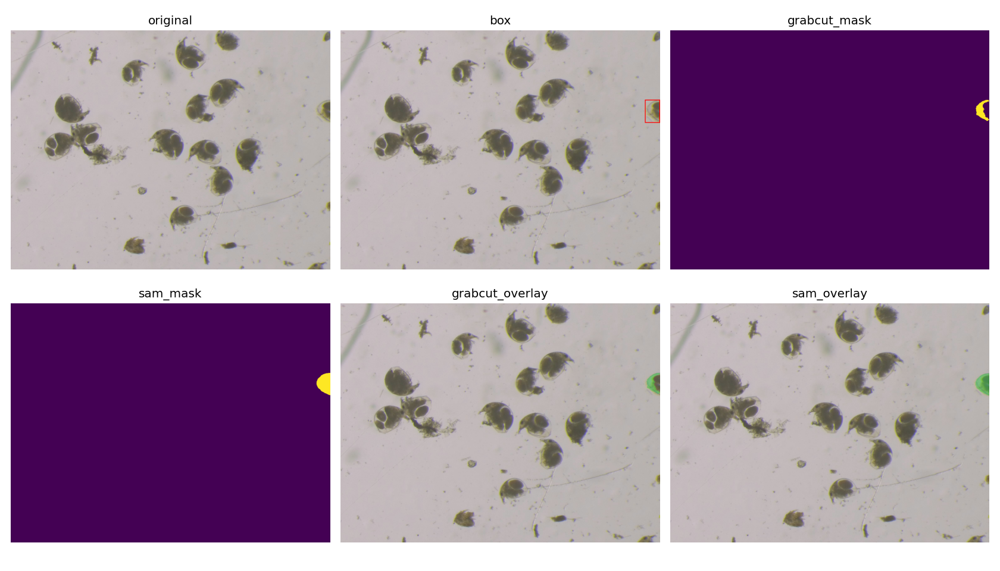

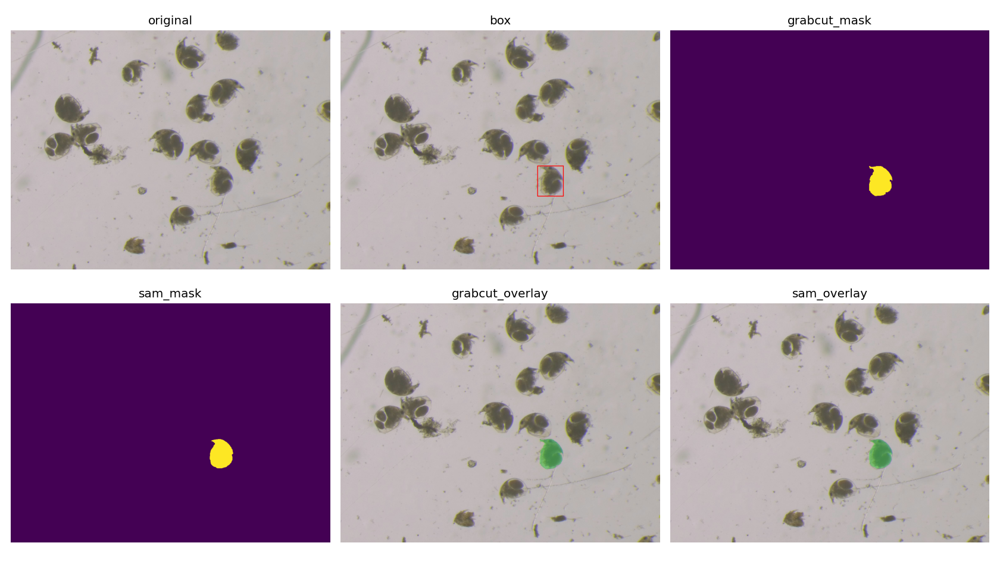

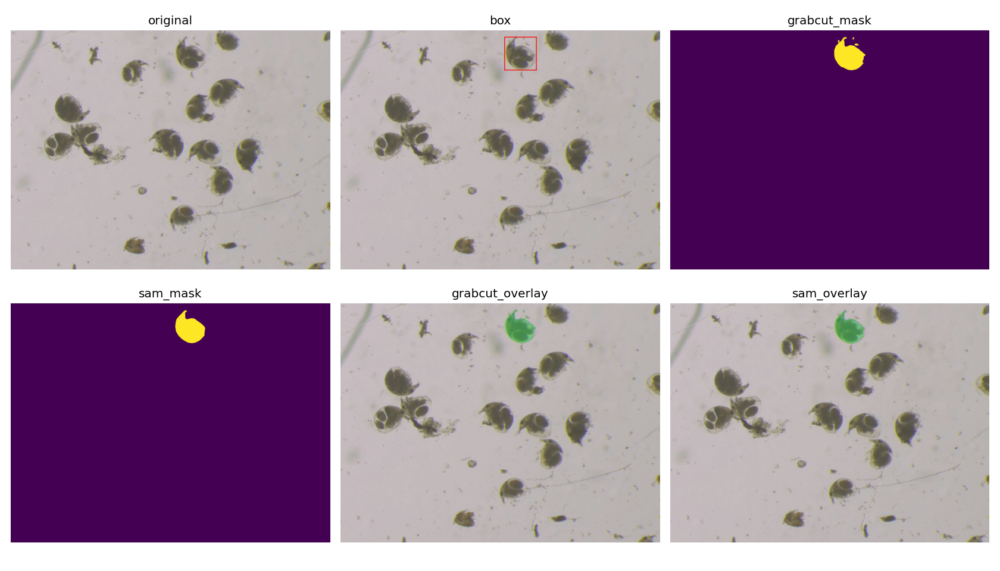

In [ ]:
# Визуально сравниваем несколько примеров сегментации
files = sorted(SEG_DIR.glob('*_original.png'))[:3]
for original_file in files:
    prefix = original_file.name.replace('_original.png', '')
    suffixes = ['_original.png', '_box.png', '_grabcut_mask.png',
                '_sam_mask.png', '_grabcut_overlay.png', '_sam_overlay.png']
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for ax, suffix in zip(axes.flat, suffixes):
        ax.imshow(Image.open(SEG_DIR / f'{prefix}{suffix}'))
        ax.set_title(suffix.replace('.png', ''))
        ax.axis('off')
    plt.tight_layout()
    fig.savefig(SEG_DIR / f'{prefix}_comparison.png', dpi=150)
    plt.show()

### Сравнение масок

Показатель `agreement_iou` — IoU между маской GrabCut и маской SAM 2.1. Если два метода выделили одинаковую область, значение близко к 1. Но оба могут одинаково ошибиться, поэтому дополнительно просмотрены сохранённые маски.

In [ ]:
if len(seg_df):
    seg_summary = (seg_df.groupby('method', as_index=False)
                   .agg(n_masks=('box_id', 'count'),
                        mean_seconds=('seconds', 'mean'),
                        mean_mask_area_pct=('mask_area_pct', 'mean')))
    display(seg_summary.round(3))
    seg_summary.to_csv(TABLE_DIR / 'segmentation_summary.csv', index=False)
else:
    print('Сравнение масок появится после задания хотя бы одной рамки.')

seg_review_file = TABLE_DIR / 'segmentation_review.csv'
if not seg_review_file.exists():
    pd.DataFrame(columns=['image_id', 'box_id', 'thin_structures', 'background_errors',
                          'overlap_quality', 'notes']).to_csv(seg_review_file, index=False)
print('Журнал визуальных ошибок:', seg_review_file.relative_to(ROOT))

method,n_masks,mean_seconds,mean_mask_area_pct
GrabCut,11,0.997,0.823
SAM 2.1,11,0.056,0.793


Журнал визуальных ошибок: results/tables/segmentation_review.csv


### Проверка рамок, которые попали на организмы

По сохранённым наложениям я отметил пять подходящих рамок: **1, 2, 5, 7 и 8**. В остальных случаях рамка выделяет точку на фоне, отдельную внутреннюю деталь или обрезанный объект. Это визуальная оценка, а не эталонная разметка.

Для пяти подходящих рамок пересчитаем IoU масок и покажем наложения. Нового запуска моделей здесь нет — используются результаты выше.

Средний IoU двух методов на 5 подходящих рамках: 0.943


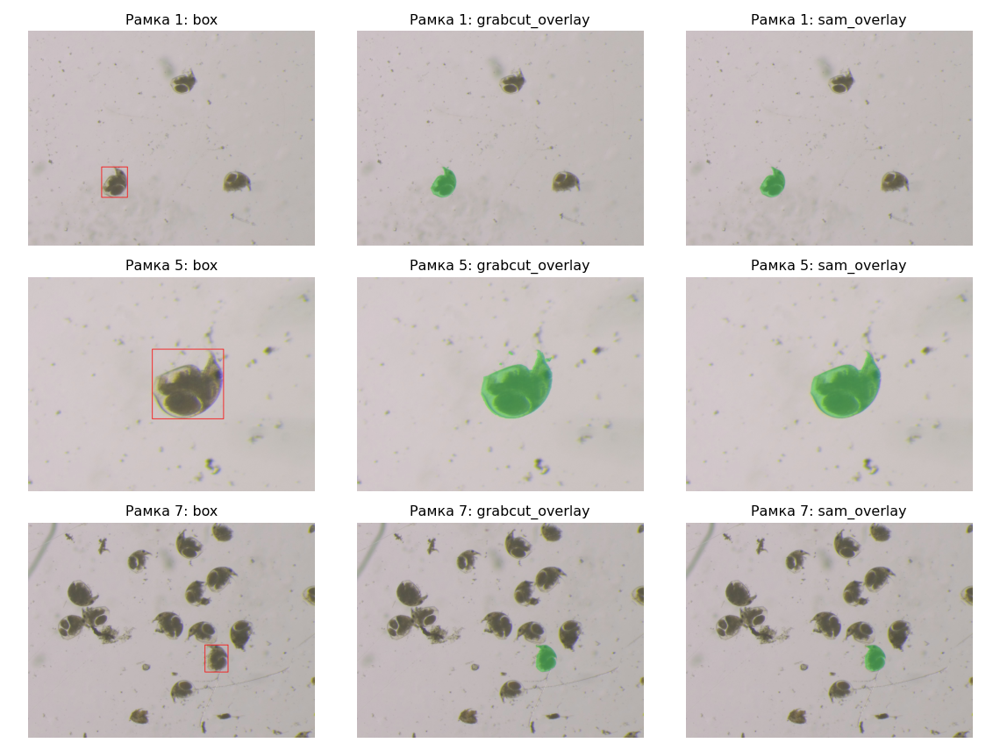

In [ ]:
good_box_ids = [1, 2, 5, 7, 8]
good_masks = seg_df[seg_df['box_id'].isin(good_box_ids)]
good_iou = good_masks.drop_duplicates('box_id')['agreement_iou'].mean()
print(f'Средний IoU двух методов на 5 подходящих рамках: {good_iou:.3f}')

# Сравним несколько наиболее показательных наложений
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for row, box_id in enumerate([1, 5, 7]):
    original_file = list(SEG_DIR.glob(f'*__{box_id:02d}_original.png'))[0]
    prefix = original_file.name.replace('_original.png', '')
    for col, suffix in enumerate(['box', 'grabcut_overlay', 'sam_overlay']):
        with Image.open(SEG_DIR / f'{prefix}_{suffix}.png') as img:
            axes[row, col].imshow(img)
        axes[row, col].set_title(f'Рамка {box_id}: {suffix}')
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

**Наблюдение.** На рамке 5 изображение организма выделено относительно полно, а для рамок 1 и 7 методы дают близкие по форме маски. При этом слабоконтрастные отростки и прозрачная оболочка частично остаются снаружи. Средний IoU двух методов по этой отобранной пятёрке — **0,943**, но он не показывает, чья маска точнее. Пять рамок отобраны по виду результата, поэтому это только качественная проверка удачных случаев, а не независимая оценка качества алгоритмов.

**Время работы.** В обновлённом запуске среднее время GrabCut составило **0,997 с**, SAM 2.1 — **0,056 с** на рамку. Первый вызов SAM в этом запуске занял **0,231 с**, последующие — примерно 0,03–0,05 с. Эти значения зависят от оборудования, прогрева и выбранной реализации; сравнение не является универсальным тестом скорости.

## 4. Сводка результатов

Ниже приведены четыре группы детекции, устойчивость рамок и средние показатели сегментации. Подробные данные и заметки по отдельным кадрам сохранены в `results/tables/`.

In [ ]:
print('ЧЕТЫРЕ ГРУППЫ ДЕТЕКЦИИ:')
display(summary_df.round(3))
print('\nУСТОЙЧИВОСТЬ РАМОК (IoU между предсказаниями, не с GT):')
display(stability_df.groupby(['model', 'augmentation'], as_index=False)['mean_best_iou'].mean().round(3))
print('\nСЕГМЕНТАЦИЯ:')
if len(seg_df):
    display(seg_summary.round(3))
else:
            print('Нет рамок для сравнения. Проверьте ручные координаты в разделе сегментации.')

# Сохраняем параметры для воспроизводимости
config = {
    'seed': SEED,
    'n_source_files': len(df),
    'n_original_files': len(original_df),
    'n_derived_files': len(df) - len(original_df),
    'n_experiment_images': len(experiment_df),
    'device': DEVICE,
    'max_side': MAX_SIDE,
    'confidence_threshold': CONF_THRESHOLD,
    'max_detections': MAX_DETECTIONS,
    'yolo_weights': 'yolo11n.pt',
    'faster_rcnn_weights': 'FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT',
    'sam_weights': 'facebook/sam2.1-hiera-tiny',
    'augmentations': experiment_augs,
    'pytorch_version': torch.__version__
}
with open(TABLE_DIR / 'experiment_config.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

ЧЕТЫРЕ ГРУППЫ ДЕТЕКЦИИ:


model,group,n_runs,mean_seconds,mean_detections
Faster R-CNN,augmented,40,0.034,7.425
Faster R-CNN,original,8,0.035,8.625
YOLO,augmented,40,0.012,2.900
YOLO,original,8,0.014,2.750


УСТОЙЧИВОСТЬ РАМОК (IoU между предсказаниями, не с GT):


model,augmentation,mean_best_iou
Faster R-CNN,blur_1,0.863
Faster R-CNN,brightness_1.2,0.826
Faster R-CNN,contrast_0.7,0.822
Faster R-CNN,flip,0.749
Faster R-CNN,noise_10,0.781
YOLO,blur_1,0.666
YOLO,brightness_1.2,0.815
YOLO,contrast_0.7,0.597
YOLO,flip,0.656
YOLO,noise_10,0.821


СЕГМЕНТАЦИЯ:


method,n_masks,mean_seconds,mean_mask_area_pct
GrabCut,11,0.997,0.823
SAM 2.1,11,0.056,0.793


## 5. Итоговые выводы

**Изображения.** В папке было 189 файлов, из них 21 похож на производные кропы. Для эксперимента оставлены 168 исходных фотографий. Разрешения отличаются, а у некоторых организмов прозрачные границы почти сливаются с фоном. На кадрах встречаются мелкий мусор, тонкие волокна, близко расположенные и частично обрезанные организмы.

**Аугментации.** Сильный шум и размытие затрудняют различение тонких деталей. После уменьшения контраста число предсказаний YOLO в среднем снизилось с 2,75 до 2,25 на кадр. Добавление шума `noise_10`, наоборот, увеличило его до 3,88. Это не улучшение качества: дополнительные рамки могут приходиться на частицы фона.

**Детекция.** Проведено 96 запусков двух моделей на восьми фотографиях, получено 504 рамки. На исходных кадрах YOLO в среднем работала за **13,5 мс**, Faster R-CNN — за **35,4 мс**. Faster R-CNN давала больше рамок (8,63 против 2,75 на кадр), но часто дублировала их. На некоторых снимках YOLO пропускала организм или находила только его внутренние тёмные части. Предобученные на COCO модели не распознают виды планктона и без дополнительной разметки недостаточно надёжны для этой задачи.

**Устойчивость.** По среднему IoU исходных и изменённых рамок Faster R-CNN была устойчивее в четырёх случаях из пяти. Исключение — шум `noise_10`: **0,821 у YOLO против 0,781 у Faster R-CNN**. У YOLO один кадр без исходных обнаружений исключён из среднего. Высокий IoU между рамками не доказывает правильную локализацию.

**Сегментация.** Для 11 пар масок средний IoU между GrabCut и SAM 2.1 составил **0,855**. После просмотра результатов я отдельно выделил пять рамок, где действительно видны организмы: для них согласие методов выше, **0,943**. Оба метода неплохо выделяют основные тёмные части тела, но прозрачные края и тонкие отростки сохраняются не всегда. Однозначно выбрать лучший метод по этим данным нельзя: эталонных масок нет, а выборка мала. Среднее время GrabCut — **0,997 с**, SAM 2.1 — **0,056 с** в данном запуске.

**Заключение.** Проведённые эксперименты показали, что предобученные модели детекции и сегментации можно применять к микроскопическим изображениям планктона даже без предварительной разметки. Однако качество обнаружения объектов во многом зависит от особенностей изображений: контрастности, размеров организмов, сложности фона и наличия перекрытий.

Основная проблема заключается в том, что детекторы, обученные на датасете COCO, не всегда правильно определяют границы планктонных организмов. Это также влияет на последующую сегментацию: даже при использовании SAM 2 неточная исходная рамка может приводить к выделению лишь части организма или посторонних объектов.

Таким образом, предобученные модели подходят для предварительного анализа изображений планктона, но без дополнительной адаптации их результаты требуют визуальной проверки. Для более объективной оценки в дальнейшем целесообразно разметить небольшую выборку изображений и сравнить предсказания моделей с эталонными границами и масками объектов.